<a href="https://colab.research.google.com/github/kuunalmistry/Google_Colab_Clg_Experiments_Projects/blob/main/Assignment_13_YOLO_fine_tuning_KuunalMistry_2410130.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.4 MB/s eta 0:00:00


In [ ]:
import torch
import ultralytics
print("Ultralytics version:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183
GPU available: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os
zip_path = "/content/drive/MyDrive/Assignment_13_dataset_ComputerVision/my-dataset.zip"
extract_path = "/content/my_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(os.listdir(extract_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['my-dataset']


In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO("yolov8n.pt")

In [ ]:
results = model.train(
    data="/content/my-dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/yolo_training",
    name="custom_yolov8n",
    patience=10,
    plots=True
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my-dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/yolo_training/custom_yolov8n-4/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=custom_yolov8n

In [ ]:
best_model = YOLO("/content/yolo_training/custom_yolov8n-5/weights/best.pt")


Saving img1.jpg to img1.jpg

image 1/1 /content/img1.jpg: 480x640 1 Frog, 9.6ms
Speed: 2.7ms preprocess, 9.6ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


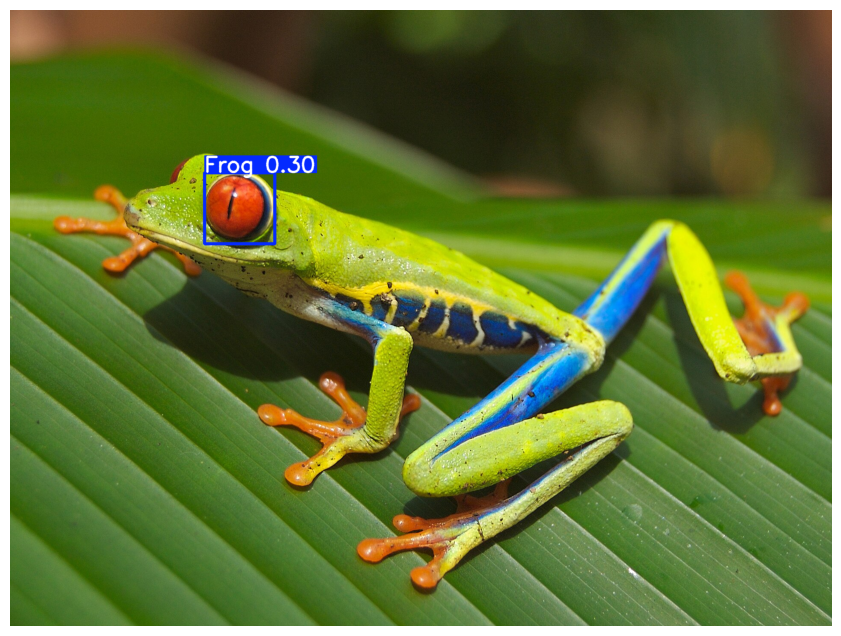

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

results = best_model.predict(source=image_path, conf=0.25, save=True)

annotated = results[0].plot()
plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])   # BGR to RGB
plt.axis("off")
plt.show()